# 1.4 — Ingesta: calidad del aire (PM2.5, PM10, O3)

**Capa 4 del protocolo.** Descarga los datos horarios crudos del Observatorio
Atmosférico Hermosillo (ERNO), de la Red Universitaria de Observatorios
Atmosféricos de la UNAM (RUOA), y los junta en una sola tabla horaria **sin
limpiar**. La limpieza y la agregación a días y meses están en
`02_procesamiento/2.4-procesamiento-calidad-aire.ipynb`.

| | |
|---|---|
| Fuente | RUOA-UNAM, observatorio ERNO (29.0814 N, 110.9706 W, 154 m) |
| Archivos | Un CSV por mes, público y sin registro: `https://ruoa.unam.mx/caire/erno/hora/AAAA-MM-ERNO_hora_L1_caire.csv` |
| Resolución | Horaria, hora local UTC-7 (Hermosillo no usa horario de verano) |
| Contaminantes | O3, SO2, NO2, NO, CO, PM10 y PM2.5; el proyecto usa PM2.5, PM10 y O3 |

Fuentes revisadas y descartadas: SINAICA (la estación de Hermosillo no tiene
datos) y Open-Meteo Air Quality (empieza en agosto de 2022).

## Entradas

- Los CSV mensuales de RUOA de `PANEL_START_YEAR` a `PANEL_END_YEAR` (2015–2020).

## Salidas

| Ruta | Contenido |
|------|-----------|
| `data/raw/aire/ruoa_erno/AAAA-MM-ERNO_hora_L1_caire.csv` | Los CSV tal como los publica RUOA |
| `data/interim/aire/aire_hermosillo_horario.csv` | `fecha_hora` y, por contaminante, el valor sin limpiar y su bandera (`pm25_ugm3`, `pm25_bandera`, ...) |

Equivalente en terminal:

```bash
python -m sonora_health_climate_eda.dataset download-air-quality-data
python -m sonora_health_climate_eda.aire horario
```

## Configuración e imports

In [2]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
import pandas as pd

from sonora_health_climate_eda.aire import HOURLY_PATH, col, consolidate_hourly, flag_col
from sonora_health_climate_eda.config import (
    AIR_QUALITY_POLLUTANTS,
    AIR_QUALITY_RAW_DIR,
    PANEL_END_YEAR,
    PANEL_START_YEAR,
    PROJ_ROOT,
)
from sonora_health_climate_eda.dataset import download_air_quality_data

# Estilo de las gráficas: una serie por panel en azul, referencias en gris.
AZUL = "#2a78d6"
GRIS = "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
    }
)
AZULES = LinearSegmentedColormap.from_list(
    "azules", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

## 1. Descarga de los CSV crudos

Un archivo por mes en `data/raw/aire/ruoa_erno/`, sin modificar. Los meses que
ya existen se omiten; con `overwrite=True` se vuelven a bajar.

In [3]:
download_air_quality_data(PANEL_START_YEAR, PANEL_END_YEAR)

archivos = sorted(AIR_QUALITY_RAW_DIR.glob("*-ERNO_hora_L1_caire.csv"))
print(f"{len(archivos)} archivos en {AIR_QUALITY_RAW_DIR.relative_to(PROJ_ROOT)}")
print(archivos[0].name, "...", archivos[-1].name)

2026-11-13 20:02:42.617 | INFO     | sonora_health_climate_eda.dataset:download_air_quality_data:307 - RUOA-ERNO en data/raw/aire/ruoa_erno: 0 meses descargados, 72 ya existían.
72 archivos en data/raw/aire/ruoa_erno
2015-01-ERNO_hora_L1_caire.csv ... 2020-12-ERNO_hora_L1_caire.csv


## 2. Formato del archivo crudo

Cada CSV trae unas líneas de metadatos (estación, zona horaria, significado de
las banderas), el encabezado, una fila de unidades y después los datos; `null`
es dato faltante. Cada contaminante tiene una columna de bandera:

| Bandera | Significado |
|---------|-------------|
| `OK` | Dato confiable |
| `BDL` | Bajo el límite de detección |
| `OR` | Fuera de rango |
| `OS` | Equipo fuera de servicio |

In [4]:
with archivos[0].open(encoding="utf-8") as f:
    print("".join(f.readlines()[:12]))

Red Universitaria de Observatorios Atmosfericos (RUOA)
Atmospheric Observatory Hermosillo (erno), Sonora
Lat 29.0814 N, Lon 110.9706 W, Alt 154 masl
Time UTC-7h
Air Quality data
Flags: OK = Reliable data, BDL = Below Detection Limit, OR = Out of Range, OS = Out of Service 
 
Time,O3,O3_flag,SO2,SO2_flag,NO2,NO2_flag,NO,NO_flag,CO,CO_flag,PM10,PM10_flag,PM2.5,PM2.5_flag
yyyy-mm-dd HH:MM:SS,ppb,flag,ppb,flag,ppb,flag,ppb,flag,ppm,flag,ug/m^3,flag,ug/m^3,flag
2015-01-01 00:00:00,29.23,OK,0.44,BDL,9.68,OK,0.96,OK,0.51,OK,10.82,OK,null,OS
2015-01-01 01:00:00,22.82,OK,0.48,BDL,11.19,OK,1.63,OK,0.5,OK,12.02,OK,null,OS
2015-01-01 02:00:00,27.72,OK,0.52,BDL,7.62,OK,0.02,BDL,0.39,OK,12.63,OK,null,OS



No todos los meses traen las mismas columnas:

In [5]:
encabezados = {}
for archivo in archivos:
    with archivo.open(encoding="utf-8") as f:
        linea = next(line for line in f if line.startswith("Time,"))
    encabezados.setdefault(linea.strip(), []).append(archivo.name[:7])

for encabezado, meses in encabezados.items():
    print(f"{len(meses)} meses ({meses[0]} a {meses[-1]}):\n  {encabezado}\n")

71 meses (2015-01 a 2020-12):
  Time,O3,O3_flag,SO2,SO2_flag,NO2,NO2_flag,NO,NO_flag,CO,CO_flag,PM10,PM10_flag,PM2.5,PM2.5_flag

1 meses (2019-11 a 2019-11):
  Time,O3,O3_flag,SO2,SO2_flag,NO2,NO2_flag,PM10,PM10_flag,PM2.5,PM2.5_flag



## 3. Tabla horaria consolidada

`consolidate_hourly` lee los archivos, valida que las unidades sean µg/m³ (PM)
y ppb (O3), se queda con PM2.5, PM10 y O3 y los junta. No cambia valores ni
banderas.

In [6]:
horario = consolidate_hourly()
horario.head()

2026-11-13 20:03:16.020 | INFO     | sonora_health_climate_eda.aire:consolidate_hourly:146 - RUOA horario: 72 archivos, 52608 horas (2015-01-01 a 2020-12-31).


,fecha_hora,pm25_ugm3,pm25_bandera,pm10_ugm3,pm10_bandera,o3_ppb,o3_bandera
0,2015-01-01 00:00:00,NaN,OS,10.82,OK,29.23,OK
1,2015-01-01 01:00:00,NaN,OS,12.02,OK,22.82,OK
2,2015-01-01 02:00:00,NaN,OS,12.63,OK,27.72,OK
3,2015-01-01 03:00:00,NaN,OS,8.45,OK,35.84,OK
4,2015-01-01 04:00:00,NaN,OS,2.88,BDL,40.27,OK


In [7]:
esperadas = pd.date_range(
    f"{PANEL_START_YEAR}-01-01", f"{PANEL_END_YEAR}-12-31 23:00", freq="h"
)
print("Horas en la tabla:", len(horario), "| esperadas:", len(esperadas))
print("Horas sin registro:", len(esperadas.difference(horario["fecha_hora"])))
print("Horas duplicadas:", int(horario["fecha_hora"].duplicated().sum()))
horario.dtypes

Horas en la tabla: 52608 | esperadas: 52608
Horas sin registro: 0
Horas duplicadas: 0


fecha_hora      datetime64[ns]
pm25_ugm3              float64
pm25_bandera            object
pm10_ugm3              float64
pm10_bandera            object
o3_ppb                 float64
o3_bandera              object
dtype: object

## 4. Banderas por año

Porcentaje de horas con cada bandera. Solo `OK` y `BDL` traen un valor que se
puede usar.

In [8]:
anio = horario["fecha_hora"].dt.year.rename("anio")
banderas = pd.concat(
    {
        pol: horario[flag_col(pol)]
        .groupby(anio)
        .value_counts(normalize=True)
        .unstack(fill_value=0)
        .reindex(columns=["OK", "BDL", "OR", "OS"], fill_value=0)
        for pol in AIR_QUALITY_POLLUTANTS
    },
    axis=1,
)
banderas.mul(100).round(1)

PM2.5                    PM10                    O3            \
pm25_bandera    OK   BDL   OR     OS    OK  BDL   OR    OS    OK  BDL   OR   
anio                                                                         
2015          65.2  17.3  3.4   14.1  88.6  1.5  1.9   8.0  83.8  0.1  0.0   
2016          79.9  18.0  2.1    0.0  97.3  1.9  0.8   0.0  87.4  0.7  0.0   
2017          79.1  19.8  1.1    0.0  94.9  4.6  0.5   0.0  99.9  0.1  0.0   
2018          37.1  20.0  1.4   41.4  57.9  0.5  0.2  41.4  57.2  1.3  0.0   
2019           0.2  65.1  0.0   34.7  94.7  3.4  1.6   0.3  96.1  3.2  0.0   
2020           0.0   0.0  0.0  100.0  94.2  3.9  1.9   0.0  98.0  2.0  0.0   

                    
pm25_bandera    OS  
anio                
2015          16.1  
2016          11.9  
2017           0.0  
2018          41.5  
2019           0.6  
2020           0.0

Rango de valores por bandera. `OR` trae valores imposibles, `BDL` trae ceros y
negativos, y hay O3 marcado `OK` por encima de 400 ppb. Todo eso se trata en 2.4.

In [9]:
valores_por_bandera = pd.concat(
    {
        pol: horario.groupby(flag_col(pol))[col(pol)].describe()[["count", "min", "50%", "max"]]
        for pol in AIR_QUALITY_POLLUTANTS
    },
    names=["contaminante", "bandera"],
)
valores_por_bandera.round(2)

count      min     50%         max
contaminante bandera                                      
PM2.5        BDL      12283.0    -4.00    0.00        3.99
             OK       22932.0     4.00    9.62      485.06
             OR         701.0 -1114.77   -6.89  3695492.43
             OS           0.0      NaN     NaN         NaN
PM10         BDL       1385.0    -4.00    0.11        3.98
             OK       46258.0     4.00   33.11      494.04
             OR         610.0 -3802.64   -9.41     5154.13
             OS           0.0      NaN     NaN         NaN
O3           BDL        651.0    -0.50    0.60        0.99
             OK       45801.0     1.00   21.56      419.76
             OR          13.0 -3627.21 -125.32      609.05
             OS           0.0      NaN     NaN         NaN

## 5. Cobertura mensual

Porcentaje de horas con valor utilizable (`OK` o `BDL`) en cada mes. Es una
vista previa: la suficiencia que cuenta (días con al menos 18 horas y meses con
al menos 75 % de días válidos) se aplica en 2.4.

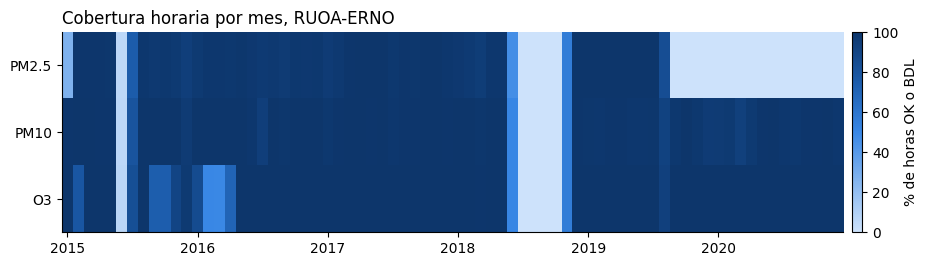

In [10]:
mes = horario["fecha_hora"].dt.to_period("M")
cobertura = pd.DataFrame(
    {
        pol: horario[flag_col(pol)].isin(["OK", "BDL"]).groupby(mes).mean() * 100
        for pol in AIR_QUALITY_POLLUTANTS
    }
)

fig, ax = plt.subplots(figsize=(12, 2.6))
im = ax.imshow(cobertura.T, aspect="auto", cmap=AZULES, vmin=0, vmax=100)
ax.grid(False)
ax.set_yticks(range(len(cobertura.columns)), cobertura.columns)
enero = [i for i, periodo in enumerate(cobertura.index) if periodo.month == 1]
ax.set_xticks(enero, [cobertura.index[i].year for i in enero])
fig.colorbar(im, ax=ax, label="% de horas OK o BDL", pad=0.01)
ax.set_title("Cobertura horaria por mes, RUOA-ERNO", loc="left")
plt.show()

In [11]:
# Meses con menos de 75 % de horas utilizables
{
    pol: cobertura.index[cobertura[pol] < 75].strftime("%Y-%m").tolist()
    for pol in AIR_QUALITY_POLLUTANTS
}

{'PM2.5': ['2015-01',
  '2015-06',
  '2015-07',
  '2018-06',
  '2018-07',
  '2018-08',
  '2018-09',
  '2018-10',
  '2018-11',
  '2019-09',
  '2019-10',
  '2019-11',
  '2019-12',
  '2020-01',
  '2020-02',
  '2020-03',
  '2020-04',
  '2020-05',
  '2020-06',
  '2020-07',
  '2020-08',
  '2020-09',
  '2020-10',
  '2020-11',
  '2020-12'],
 'PM10': ['2015-06',
  '2018-06',
  '2018-07',
  '2018-08',
  '2018-09',
  '2018-10',
  '2018-11'],
 'O3': ['2015-06',
  '2015-09',
  '2015-10',
  '2016-02',
  '2016-03',
  '2016-04',
  '2018-06',
  '2018-07',
  '2018-08',
  '2018-09',
  '2018-10',
  '2018-11']}

## 6. Guardar la tabla horaria

In [12]:
HOURLY_PATH.parent.mkdir(parents=True, exist_ok=True)
horario.to_csv(HOURLY_PATH, index=False)
print(f"{len(horario)} horas -> {HOURLY_PATH.relative_to(PROJ_ROOT)}")

52608 horas -> data/interim/aire/aire_hermosillo_horario.csv


## Hallazgos para el procesamiento (2.4)

- Están las 52,608 horas de 2015–2020: los huecos vienen como bandera `OS`, no
  como filas faltantes.
- `OR` trae valores imposibles (miles de µg/m³, negativos) y `OS` llega sin
  valor: ninguno se puede usar.
- `BDL` trae ceros y negativos. Los valores `OK` empiezan justo en 4 µg/m³ (PM)
  y 1 ppb (O3), que es el límite de detección.
- PM2.5: en 2019 casi todas las horas son `BDL` con valor cero (sensor fallando)
  y en 2020 no hay datos.
- Junio a noviembre de 2018 falla toda la estación.
- Hay O3 marcado `OK` con unos 400 ppb durante horas seguidas: es un artefacto
  del equipo, no una medición.